# Test rapide : prétraitements fisheye + détection YOLO26

On applique séparément les prétraitements de la section *Prétraitement* du rapport à des images fisheye, puis on lance YOLO26 (classe *person*, sans réentraînement) sur chacune.

| Dossier | Représentation |
|---|---|
| `0_brut` | image fisheye d'origine |
| `1_perspective` | une vue perspective |
| `2_multivues` | plusieurs vues perspectives + fusion |
| `3_cylindrique` | panorama cylindrique (axe = verticale du monde) |
| `4_erp` | équirectangulaire |

**Deux sources possibles :**
- **`fisheye8k`** : la base FishEye8K, téléchargée depuis Hugging Face sans compte. Elle contient des piétons annotés, donc on peut mesurer un **rappel**. Les caméras surveillent des carrefours en **vue plongeante** (montage « plafond ») et la base ne fournit **pas de calibration** : on suppose un modèle équidistant de 180° et on détecte le cercle image automatiquement.
- **`dossier`** : n'importe quel dossier d'images fisheye, par exemple des captures de **votre banc** (montage « horizontal »). Sans annotations, on compare le nombre et la confiance des détections, et on regarde les images.

Toutes les détections sont **ramenées dans l'image fisheye d'origine** (via les rayons 3D) pour être comparées entre elles et aux annotations.

## 0. Configuration

In [1]:
from pathlib import Path

SOURCE = "fisheye8k"             # "fisheye8k" ou "dossier"
DOSSIER = Path("/content/mes_images_fisheye")   # utilisé si SOURCE == "dossier"
MONTAGE = None                   # None = automatique ("plafond" pour FishEye8K, "horizontal" pour un dossier)
FOV_DEG = 180                    # champ supposé de l'objectif (calibration approximative)

PAR_CAMERA = 8                   # FishEye8K : nombre d'images tirées par caméra (18 caméras)
MODEL = "yolo26s.pt"             # yolo26n / s / m / l / x
CONF = 0.25                      # seuil de confiance pour compter une détection
DEVICE = None                    # None = GPU si disponible
WORK = Path("./test_pretraitements")
SEED = 0

MONTAGE = MONTAGE or ("plafond" if SOURCE == "fisheye8k" else "horizontal")
print("Montage :", MONTAGE)

Montage : plafond


## 1. Installation et code

In [2]:
%pip install -q "ultralytics>=8.4.0" huggingface_hub tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\FlowUP\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
%%writefile projections.py
"""
projections.py — Géométrie fisheye et reprojections pour la détection de personnes.

Conventions (identiques à OpenCV et à WoodScape) :
  repère caméra : x vers la droite, y vers le BAS, z le long de l'axe optique.
  repère « à niveau » (L) : même convention, mais y_L = verticale du monde (vers le bas)
  et z_L = axe optique projeté sur le plan horizontal. Toutes les représentations
  (perspective, multivues, cylindrique, ERP) sont construites dans ce repère L, de sorte
  que les verticales du monde restent verticales dans l'image.

Chaque représentation fournit :
  - .W, .H             taille de l'image cible
  - .pixel_to_dir(u,v) directions unitaires (repère L) pour des pixels cibles
  - .dir_to_pixel(d)   pixels cibles (u,v) + masque de validité pour des directions
Le principe est toujours la reprojection inverse (backward mapping) : on part de la
grille cible, on remonte au rayon, puis au pixel fisheye -> table de correspondance (LUT).
"""
from __future__ import annotations

import json
import math
from dataclasses import dataclass, field

import cv2
import numpy as np
from scipy.spatial.transform import Rotation


# --------------------------------------------------------------------------------------
# Modèles de caméra fisheye
# --------------------------------------------------------------------------------------
class _RadialFisheye:
    """Base commune : loi radiale rho(theta) monotone, inversée par table."""

    W: int
    H: int
    cx: float
    cy: float
    theta_lim: float

    def _radial(self, theta):  # rho en pixels (axe x)
        raise NotImplementedError

    def _build_inverse(self, theta_cap_deg: float):
        th = np.linspace(0.0, math.radians(theta_cap_deg), 40001)
        rho = self._radial(th)
        d = np.diff(rho)
        stop = int(np.argmax(d <= 0)) if np.any(d <= 0) else len(d)
        self.theta_lim = float(th[stop])          # domaine où la loi est injective
        self._th_tab, self._rho_tab = th[: stop + 1], rho[: stop + 1]

    @property
    def f0(self) -> float:
        """Résolution au centre (pixels par radian) = dérivée de rho en 0."""
        return float((self._radial(np.array([1e-4])) / 1e-4)[0])

    def project(self, d):
        """Directions (...,3) du repère caméra -> (u, v, valide)."""
        d = np.asarray(d, dtype=np.float64)
        x, y, z = d[..., 0], d[..., 1], d[..., 2]
        chi = np.hypot(x, y)
        theta = np.arctan2(chi, z)
        rho = self._radial(theta)
        with np.errstate(invalid="ignore", divide="ignore"):
            s = np.where(chi > 1e-12, rho / chi, 0.0)
        u = self.cx + s * x
        v = self.cy + s * y * self._aspect
        valid = (theta <= self.theta_lim) & (u >= -0.5) & (u <= self.W - 0.5) \
            & (v >= -0.5) & (v <= self.H - 0.5)
        return u, v, valid

    def unproject(self, u, v):
        """Pixels fisheye -> directions unitaires (repère caméra)."""
        xp = np.asarray(u, dtype=np.float64) - self.cx
        yp = (np.asarray(v, dtype=np.float64) - self.cy) / self._aspect
        rho = np.hypot(xp, yp)
        theta = np.interp(rho, self._rho_tab, self._th_tab)
        with np.errstate(invalid="ignore", divide="ignore"):
            s = np.where(rho > 1e-12, np.sin(theta) / rho, 0.0)
        return np.stack([s * xp, s * yp, np.cos(theta)], axis=-1)


class WoodScapeFisheye(_RadialFisheye):
    """Modèle WoodScape : rho(theta) = k1 θ + k2 θ² + k3 θ³ + k4 θ⁴ (rho en pixels).

    Conforme à scripts/calibration/projection.py du dépôt valeoai/WoodScape :
      u = u' + cx_offset + W/2 - 0.5 ;  v = v' * aspect_ratio + cy_offset + H/2 - 0.5
    L'extrinsèque (quaternion x,y,z,w) donne la rotation caméra -> véhicule (ISO 8855 :
    x avant, y gauche, z haut).
    """

    def __init__(self, k, width, height, cx_offset=0.0, cy_offset=0.0, aspect_ratio=1.0,
                 R_cam2world=None, name="", theta_cap_deg=100.0):
        self.k = np.asarray(k, dtype=np.float64)
        self.W, self.H = int(width), int(height)
        self.cx = 0.5 * self.W - 0.5 + cx_offset
        self.cy = 0.5 * self.H - 0.5 + cy_offset
        self._aspect = float(aspect_ratio)
        self.R_cam2world = None if R_cam2world is None else np.asarray(R_cam2world, float)
        self.world_down = np.array([0.0, 0.0, -1.0])   # ISO 8855 : z vers le haut
        self.name = name
        self._build_inverse(theta_cap_deg)

    def _radial(self, theta):
        t = np.asarray(theta, dtype=np.float64)
        k1, k2, k3, k4 = self.k
        return t * (k1 + t * (k2 + t * (k3 + t * k4)))

    @classmethod
    def from_json(cls, path_or_dict):
        cfg = path_or_dict
        if not isinstance(cfg, dict):
            with open(cfg) as f:
                cfg = json.load(f)
        it = cfg["intrinsic"]
        R = Rotation.from_quat(cfg["extrinsic"]["quaternion"]).as_matrix()
        return cls([it["k1"], it["k2"], it["k3"], it["k4"]], it["width"], it["height"],
                   it.get("cx_offset", 0.0), it.get("cy_offset", 0.0),
                   it.get("aspect_ratio", 1.0), R_cam2world=R, name=cfg.get("name", ""))

    def key(self):
        """Clé de cache : deux images de même calibration partagent les mêmes LUT."""
        R = None if self.R_cam2world is None else np.round(self.R_cam2world, 6).tobytes()
        return (tuple(np.round(self.k, 6)), self.W, self.H, round(self.cx, 4),
                round(self.cy, 4), self._aspect, R)


class KannalaBrandtFisheye(_RadialFisheye):
    """Modèle OpenCV fisheye (Kannala-Brandt), pour votre propre banc :
    θ_d = θ (1 + k1 θ² + k2 θ⁴ + k3 θ⁶ + k4 θ⁸) ;  u = fx θ_d x/r + cx ;  v = fy θ_d y/r + cy.
    `R_cam2world` et `world_down` sont optionnels (sinon, pas de mise à niveau).
    """

    def __init__(self, K, D, width, height, R_cam2world=None, world_down=(0, 1, 0),
                 name="", theta_cap_deg=100.0):
        K = np.asarray(K, float)
        self.fx, self.fy = K[0, 0], K[1, 1]
        self.cx, self.cy = K[0, 2], K[1, 2]
        self.D = np.asarray(D, float).ravel()[:4]
        self.W, self.H = int(width), int(height)
        self._aspect = self.fy / self.fx
        self.R_cam2world = None if R_cam2world is None else np.asarray(R_cam2world, float)
        self.world_down = np.asarray(world_down, float)
        self.name = name
        self._build_inverse(theta_cap_deg)

    def _radial(self, theta):
        t = np.asarray(theta, dtype=np.float64)
        t2 = t * t
        k1, k2, k3, k4 = self.D
        return self.fx * t * (1 + t2 * (k1 + t2 * (k2 + t2 * (k3 + t2 * k4))))

    def key(self):
        return (self.fx, self.fy, self.cx, self.cy, tuple(self.D), self.W, self.H)


class EquidistantFisheye(KannalaBrandtFisheye):
    """Calibration APPROXIMATIVE quand on n'a pas de calibration : modèle équidistant
    (r = f θ) dont le cercle image (centre, rayon) correspond au champ `fov_deg`."""

    def __init__(self, cx, cy, radius, fov_deg, width, height, name=""):
        f = radius / math.radians(fov_deg / 2)
        K = np.array([[f, 0, cx], [0, f, cy], [0, 0, 1]])
        super().__init__(K, [0, 0, 0, 0], width, height, name=name, theta_cap_deg=fov_deg / 2)
        self.radius, self.fov_deg = radius, fov_deg


def estimate_image_circle(images, threshold=20):
    """Estime le cercle utile d'images fisheye (bord noir) : renvoie (cx, cy, rayon, fiable).

    On prend le maximum de plusieurs images (le bord noir ne bouge pas), on garde la plus
    grande zone claire, puis on ajuste un cercle sur son contour en ignorant les points
    collés au bord du cadre (cercle rogné). Sans bord noir visible : cercle inscrit, fiable=False.
    """
    g = np.max([cv2.cvtColor(im, cv2.COLOR_BGR2GRAY) for im in images], axis=0)
    H, W = g.shape
    m = (cv2.GaussianBlur(g, (5, 5), 0) > threshold).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((7, 7), np.uint8))
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if cnts:
        c = max(cnts, key=cv2.contourArea)[:, 0, :].astype(float)
        keep = (c[:, 0] > 3) & (c[:, 0] < W - 4) & (c[:, 1] > 3) & (c[:, 1] < H - 4)
        if keep.sum() > 100:
            x, y = c[keep, 0], c[keep, 1]
            A = np.stack([2 * x, 2 * y, np.ones_like(x)], 1)
            (a, b, k), *_ = np.linalg.lstsq(A, x * x + y * y, rcond=None)
            r = math.sqrt(k + a * a + b * b)
            if 0.2 * min(W, H) < r < 1.5 * max(W, H):
                return float(a), float(b), float(r), True
    return (W - 1) / 2, (H - 1) / 2, min(W, H) / 2, False


# --------------------------------------------------------------------------------------
# Repère à niveau
# --------------------------------------------------------------------------------------
def level_frame(cam, mounting: str = "auto", extra_pitch_deg: float = 0.0) -> np.ndarray:
    """Matrice M (3x3) telle que d_cam = M @ d_L.

    Le repère à niveau L a son axe y_L sur la verticale du monde (vers le bas) : c'est
    l'axe du cylindre, donc ce qui rend les personnes debout verticales dans l'image.
      - "horizontal" : caméra à l'horizontale (votre banc) -> L = repère caméra ;
      - "plafond"    : caméra qui regarde vers le bas (mât, plafond) -> y_L = axe optique,
                       z_L = direction du haut de l'image ;
      - "auto"       : utilise l'extrinsèque si la caméra en a une (WoodScape), sinon horizontal.
    """
    if mounting == "plafond":
        M = np.stack([[1.0, 0, 0], [0, 0, 1.0], [0, -1.0, 0]], axis=1)
    elif mounting == "horizontal" or getattr(cam, "R_cam2world", None) is None:
        M = np.eye(3)
    else:
        down = cam.R_cam2world.T @ cam.world_down          # verticale vers le bas, repère caméra
        yL = down / np.linalg.norm(down)
        z = np.array([0.0, 0.0, 1.0])
        zL = z - (z @ yL) * yL
        n = np.linalg.norm(zL)
        if n < 0.2:
            raise ValueError("Axe optique proche de la verticale : utiliser mounting='plafond'.")
        zL /= n
        M = np.stack([np.cross(yL, zL), yL, zL], axis=1)
    if extra_pitch_deg:
        M = M @ Rotation.from_euler("x", -extra_pitch_deg, degrees=True).as_matrix()
    return M


def tilt_deg(cam) -> float:
    """Inclinaison de l'axe optique sous l'horizontale (degrés, >0 = vers le bas)."""
    if getattr(cam, "R_cam2world", None) is None:
        return float("nan")
    down = cam.R_cam2world.T @ cam.world_down
    down /= np.linalg.norm(down)
    return float(np.degrees(np.arcsin(np.clip(down[2], -1, 1))))


# --------------------------------------------------------------------------------------
# Représentations cibles (toutes exprimées dans le repère à niveau L)
# --------------------------------------------------------------------------------------
def _grid(W, H):
    return np.meshgrid(np.arange(W, dtype=np.float64), np.arange(H, dtype=np.float64))


class Perspective:
    """Vue perspective virtuelle de focale f (px), champ horizontal hfov, tournée de
    yaw_deg autour de la verticale (yaw > 0 = vers la droite)."""

    kind = "perspective"

    def __init__(self, f, hfov_deg, vfov_deg, yaw_deg=0.0, pitch_deg=0.0):
        """Perspective virtuelle : focale f (px), champ hfov × vfov, orientée par lacet/tangage."""
        self.f = float(f)
        self.W = int(round(2 * f * math.tan(math.radians(hfov_deg) / 2)))
        self.H = int(round(2 * f * math.tan(math.radians(vfov_deg) / 2)))
        self.cx, self.cy = (self.W - 1) / 2, (self.H - 1) / 2
        # d_L = R d_local, avec R = Ry(lacet) · Rx(-tangage) : tangage > 0 = vers le bas
        self.R = Rotation.from_euler("YX", [yaw_deg, -pitch_deg], degrees=True).as_matrix()
        self.yaw, self.pitch = yaw_deg, pitch_deg

    def pixel_to_dir(self, u, v):
        x = (np.asarray(u, float) - self.cx) / self.f
        y = (np.asarray(v, float) - self.cy) / self.f
        d = np.stack([x, y, np.ones_like(x)], axis=-1)
        d /= np.linalg.norm(d, axis=-1, keepdims=True)
        return d @ self.R.T

    def dir_to_pixel(self, d):
        dl = np.asarray(d, float) @ self.R          # repère local de la vue
        z = dl[..., 2]
        with np.errstate(invalid="ignore", divide="ignore"):
            u = self.cx + self.f * dl[..., 0] / z
            v = self.cy + self.f * dl[..., 1] / z
        valid = (z > 1e-6) & (u >= -0.5) & (u <= self.W - 0.5) & (v >= -0.5) & (v <= self.H - 0.5)
        return u, v, valid


class Cylindrical:
    """Cylindre vertical déroulé : u = cx + f ψ, v = cy + f tan(ε) (ε > 0 vers le bas)."""

    kind = "cylindrique"

    def __init__(self, f, hfov_deg=180.0, up_deg=55.0, down_deg=55.0):
        self.f = float(f)
        self.W = int(round(f * math.radians(hfov_deg)))
        self.h_up, self.h_down = math.tan(math.radians(up_deg)), math.tan(math.radians(down_deg))
        self.H = int(round(f * (self.h_up + self.h_down)))
        self.cx = (self.W - 1) / 2
        self.cy = f * self.h_up - 0.5          # ligne d'horizon

    def pixel_to_dir(self, u, v):
        psi = (np.asarray(u, float) - self.cx) / self.f
        h = (np.asarray(v, float) - self.cy) / self.f
        d = np.stack([np.sin(psi), h, np.cos(psi)], axis=-1)
        return d / np.sqrt(1 + h * h)[..., None]

    def dir_to_pixel(self, d):
        d = np.asarray(d, float)
        r = np.hypot(d[..., 0], d[..., 2])
        psi = np.arctan2(d[..., 0], d[..., 2])
        with np.errstate(invalid="ignore", divide="ignore"):
            h = d[..., 1] / r
        u, v = self.cx + self.f * psi, self.cy + self.f * h
        valid = (r > 1e-6) & (u >= -0.5) & (u <= self.W - 0.5) & (v >= -0.5) & (v <= self.H - 0.5)
        return u, v, valid


class Equirectangular:
    """ERP : u = cx + k λ, v = cy + k φ avec φ = arcsin(d_y) (>0 vers le bas).
    Attention au signe : avec y vers le bas (OpenCV), écrire v = H(1/2 - φ/ΔΦ) avec
    φ = arcsin(d_y) donne une image À L'ENVERS. Ici le haut de l'image est bien le ciel."""

    kind = "erp"

    def __init__(self, k, hfov_deg=180.0, up_deg=80.0, down_deg=80.0):
        self.k = float(k)
        self.W = int(round(k * math.radians(hfov_deg)))
        self.H = int(round(k * math.radians(up_deg + down_deg)))
        self.cx = (self.W - 1) / 2
        self.cy = k * math.radians(up_deg) - 0.5        # ligne d'horizon

    def pixel_to_dir(self, u, v):
        lam = (np.asarray(u, float) - self.cx) / self.k
        phi = (np.asarray(v, float) - self.cy) / self.k
        return np.stack([np.cos(phi) * np.sin(lam), np.sin(phi), np.cos(phi) * np.cos(lam)], -1)

    def dir_to_pixel(self, d):
        d = np.asarray(d, float)
        lam = np.arctan2(d[..., 0], d[..., 2])
        phi = np.arcsin(np.clip(d[..., 1], -1, 1))
        u, v = self.cx + self.k * lam, self.cy + self.k * phi
        valid = (u >= -0.5) & (u <= self.W - 0.5) & (v >= -0.5) & (v <= self.H - 0.5)
        return u, v, valid


class FisheyeView:
    """L'image fisheye d'origine présentée comme une « représentation » du repère L :
    permet de ramener les boîtes de n'importe quelle représentation dans l'image brute."""

    kind = "fisheye"

    def __init__(self, cam, M):
        self.cam, self.M, self.W, self.H = cam, M, cam.W, cam.H

    def pixel_to_dir(self, u, v):
        return self.cam.unproject(u, v) @ self.M

    def dir_to_pixel(self, d):
        return self.cam.project(np.asarray(d, float) @ self.M.T)


# --------------------------------------------------------------------------------------
# Tables de correspondance (LUT) et remappage
# --------------------------------------------------------------------------------------
@dataclass
class Lut:
    map_x: np.ndarray          # float32 (H,W) : abscisse fisheye, -1 si hors champ
    map_y: np.ndarray
    valid: np.ndarray          # bool (H,W)
    xi: np.ndarray = field(repr=False, default=None)   # versions entières (plus proche voisin)
    yi: np.ndarray = field(repr=False, default=None)

    def remap(self, img, interp=cv2.INTER_LINEAR):
        return cv2.remap(img, self.map_x, self.map_y, interp,
                         borderMode=cv2.BORDER_CONSTANT, borderValue=0)


def build_lut(cam, target, M_level: np.ndarray) -> Lut:
    """Reprojection inverse : pixel cible -> direction (repère L) -> repère caméra -> pixel fisheye."""
    uu, vv = _grid(target.W, target.H)
    d_L = target.pixel_to_dir(uu, vv)
    d_cam = d_L @ M_level.T
    u, v, valid = cam.project(d_cam)
    mx = np.where(valid, u, -1).astype(np.float32)
    my = np.where(valid, v, -1).astype(np.float32)
    xi = np.clip(np.rint(mx), 0, cam.W - 1).astype(np.int16)
    yi = np.clip(np.rint(my), 0, cam.H - 1).astype(np.int16)
    return Lut(mx, my, valid, xi, yi)


def identity_lut(cam) -> Lut:
    uu, vv = _grid(cam.W, cam.H)
    valid = np.ones((cam.H, cam.W), bool)
    return Lut(uu.astype(np.float32), vv.astype(np.float32), valid,
               uu.astype(np.int16), vv.astype(np.int16))


# --------------------------------------------------------------------------------------
# Jeu de représentations à comparer
# --------------------------------------------------------------------------------------
REPRESENTATIONS = ["0_brut", "1_perspective", "2_multivues", "3_cylindrique", "4_erp"]

# Réglages par montage. Angles en degrés ; pitch > 0 = vue tournée vers le bas.
PRESETS = {
    # caméra horizontale (votre banc) : panorama de 180° devant la caméra
    "horizontal": dict(persp=dict(hfov=110, vfov=90, pitch=0),
                       mv=dict(yaws=(-55, 0, 55), pitch=0, hfov=75, vfov=90),
                       cyl=dict(hfov=180, up=55, down=55),
                       erp=dict(hfov=180, up=80, down=80)),
    # caméra qui regarde vers le bas (FishEye8K) : panorama de 360° autour de la verticale
    "plafond": dict(persp=dict(hfov=120, vfov=120, pitch=90),
                    mv=dict(yaws=(0, 90, 180, 270), pitch=35, hfov=95, vfov=95),
                    cyl=dict(hfov=380, up=5, down=65),     # 380° : recouvrement à la jointure
                    erp=dict(hfov=380, up=5, down=85)),
}


def make_representations(cam, mounting="horizontal", scale=1.0, overrides=None) -> dict:
    """Construit les 5 représentations pour une caméra.

    Toutes ont la même résolution angulaire au centre : f = f0 de la caméra × scale.
    Renvoie {nom: {'views': [(target, lut), ...], 'M': M, 'fisheye': FisheyeView}}.
    """
    preset = PRESETS["plafond" if mounting == "plafond" else "horizontal"]
    p = {k: dict(v) for k, v in preset.items()}
    for k, v in (overrides or {}).items():
        p[k].update(v)
    f = cam.f0 * scale
    M = level_frame(cam, mounting)
    fe = FisheyeView(cam, M)
    reps = {"0_brut": {"views": [(fe, identity_lut(cam))]}}
    q = p["persp"]
    t = Perspective(f, q["hfov"], q["vfov"], pitch_deg=q["pitch"])
    reps["1_perspective"] = {"views": [(t, build_lut(cam, t, M))]}
    q = p["mv"]
    views = [Perspective(f, q["hfov"], q["vfov"], yaw_deg=y, pitch_deg=q["pitch"]) for y in q["yaws"]]
    reps["2_multivues"] = {"views": [(t, build_lut(cam, t, M)) for t in views]}
    q = p["cyl"]
    t = Cylindrical(f, q["hfov"], q["up"], q["down"])
    reps["3_cylindrique"] = {"views": [(t, build_lut(cam, t, M))]}
    q = p["erp"]
    t = Equirectangular(f, q["hfov"], q["up"], q["down"])
    reps["4_erp"] = {"views": [(t, build_lut(cam, t, M))]}
    for name, r in reps.items():
        r["M"], r["fisheye"] = M, fe
        # doublons possibles : plusieurs vues, ou panorama qui se recouvre au-delà de 360°
        r["dedup"] = len(r["views"]) > 1 or (name in ("3_cylindrique", "4_erp")
                                             and p["cyl" if name == "3_cylindrique" else "erp"]["hfov"] > 360)
    return reps


# --------------------------------------------------------------------------------------
# Passage de boîtes entre représentations (fusion multivues)
# --------------------------------------------------------------------------------------
def box_outline(box, n=16):
    """Points régulièrement espacés sur le contour d'une boîte (x1,y1,x2,y2)."""
    x1, y1, x2, y2 = box
    t = np.linspace(0, 1, n, endpoint=False)
    top = np.stack([x1 + t * (x2 - x1), np.full_like(t, y1)], 1)
    right = np.stack([np.full_like(t, x2), y1 + t * (y2 - y1)], 1)
    bot = np.stack([x2 - t * (x2 - x1), np.full_like(t, y2)], 1)
    left = np.stack([np.full_like(t, x1), y2 - t * (y2 - y1)], 1)
    return np.concatenate([top, right, bot, left])


def transfer_box(box, src, dst):
    """Boîte dans la représentation src -> boîte englobante dans dst (via les rayons)."""
    pts = box_outline(box)
    d = src.pixel_to_dir(pts[:, 0], pts[:, 1])
    u, v, ok = dst.dir_to_pixel(d)
    if ok.sum() < 3:
        return None
    u, v = u[ok], v[ok]
    return np.array([max(u.min(), 0), max(v.min(), 0),
                     min(u.max(), dst.W - 1), min(v.max(), dst.H - 1)])


def box_iou(a, b):
    """IoU entre deux ensembles de boîtes (N,4) et (M,4)."""
    a, b = np.asarray(a, float).reshape(-1, 4), np.asarray(b, float).reshape(-1, 4)
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0]); iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2]); iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); ab = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / np.maximum(aa[:, None] + ab[None, :] - inter, 1e-9)


def nms(boxes, scores, iou_thr=0.5):
    boxes, scores = np.asarray(boxes, float).reshape(-1, 4), np.asarray(scores, float)
    order, keep = np.argsort(-scores), []
    while order.size:
        i = order[0]
        keep.append(i)
        if order.size == 1:
            break
        ious = box_iou(boxes[i:i + 1], boxes[order[1:]])[0]
        order = order[1:][ious < iou_thr]
    return np.array(keep, dtype=int)


def fuse_multiview(dets_per_view, views, dst, iou_thr=0.5):
    """Ramène les détections de chaque vue dans la représentation dst (ex. cylindrique),
    puis supprime les doublons entre vues par NMS. dets_per_view : [(boxes, scores), ...]."""
    B, S = [], []
    for (boxes, scores), (target, _) in zip(dets_per_view, views):
        for b, s in zip(boxes, scores):
            tb = transfer_box(b, target, dst)
            if tb is not None and tb[2] > tb[0] and tb[3] > tb[1]:
                B.append(tb); S.append(s)
    if not B:
        return np.zeros((0, 4)), np.zeros(0)
    B, S = np.array(B), np.array(S)
    k = nms(B, S, iou_thr)
    return B[k], S[k]


# --------------------------------------------------------------------------------------
# Contrôles géométriques
# --------------------------------------------------------------------------------------
def check_roundtrip(cam, n=20000, seed=0):
    """Erreur (px) de l'aller-retour pixel -> direction -> pixel sur l'image fisheye."""
    rng = np.random.default_rng(seed)
    u, v = rng.uniform(0, cam.W - 1, n), rng.uniform(0, cam.H - 1, n)
    d = cam.unproject(u, v)
    th = np.arccos(np.clip(d[:, 2], -1, 1))
    m = th < cam.theta_lim * 0.999
    u2, v2, _ = cam.project(d[m])
    return float(np.max(np.hypot(u2 - u[m], v2 - v[m])))


def check_target_roundtrip(target, n=20000, seed=0):
    rng = np.random.default_rng(seed)
    u, v = rng.uniform(0, target.W - 1, n), rng.uniform(0, target.H - 1, n)
    u2, v2, _ = target.dir_to_pixel(target.pixel_to_dir(u, v))
    du = u2 - u
    scale = getattr(target, "f", None) if target.kind == "cylindrique" else getattr(target, "k", None)
    if target.kind in ("cylindrique", "erp") and scale:          # panorama > 360° : même rayon, 2 colonnes
        period = 2 * math.pi * scale
        du = np.minimum(np.abs(du), np.abs(np.abs(du) - period))
    return float(np.max(np.hypot(du, v2 - v)))


def check_vertical_line(target, azimuth_deg=60.0, elev_range_deg=(-40, 40)):
    """Une verticale du monde (azimut fixe) doit rester une colonne : renvoie l'écart max en u."""
    e = np.radians(np.linspace(*elev_range_deg, 50))
    a = math.radians(azimuth_deg)
    d = np.stack([np.cos(e) * math.sin(a), np.sin(e), np.cos(e) * math.cos(a)], 1)
    u, _, ok = target.dir_to_pixel(d)
    return float(np.ptp(u[ok])) if ok.any() else float("nan")


def check_upright(target):
    """Au centre de la vue, un point légèrement plus haut dans le monde doit apparaître plus
    haut dans l'image (v plus petit). Renvoie None si la vue regarde à la verticale (nadir)."""
    d0 = target.pixel_to_dir(np.array([(target.W - 1) / 2]), np.array([(target.H - 1) / 2]))[0]
    if abs(d0[1]) > 0.95:
        return None
    up = d0 - np.array([0.0, 0.05, 0.0]); up /= np.linalg.norm(up)
    _, v0, _ = target.dir_to_pixel(d0[None]); _, v1, _ = target.dir_to_pixel(up[None])
    return bool(v1[0] < v0[0])

Writing projections.py


In [3]:
%%writefile outils.py
"""
outils.py — Chargement des images, détection YOLO26 sur chaque représentation, comparaison.

Toutes les détections sont ramenées dans l'image fisheye d'origine (via les rayons), ce qui
permet de les comparer entre représentations et, si elles existent, aux annotations.
"""
from __future__ import annotations

import json
import math
import random
import time
from collections import defaultdict
from pathlib import Path

import cv2
import numpy as np

from projections import box_iou, nms, transfer_box

IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}


# --------------------------------------------------------------------------------------
# FishEye8K (Hugging Face, format FiftyOne : samples.json + data/)
# --------------------------------------------------------------------------------------
def read_fisheye8k_index(samples_json):
    """Liste des échantillons : chemin relatif, caméra, découpage, boîtes relatives [x,y,w,h]."""
    with open(samples_json) as f:
        data = json.load(f)
    samples = data["samples"] if isinstance(data, dict) else data
    out = []
    for s in samples:
        fp = s["filepath"]
        rel = fp[fp.index("data/"):] if "data/" in fp else "data/" + Path(fp).name
        dets = (s.get("detections") or {}).get("detections", [])
        name = Path(rel).name
        loc = s.get("location") or name.split("_")[0]
        out.append(dict(rel=rel, name=name, location=str(loc), split=",".join(s.get("tags", [])),
                        gt=[(d.get("label"), d.get("bounding_box")) for d in dets]))
    return out


def select_samples(index, per_location=8, label="Pedestrian", min_count=1, seed=0):
    """Tire `per_location` images par caméra, parmi celles qui contiennent au moins
    `min_count` objets de la classe `label` (couvre toutes les caméras, toutes les heures)."""
    by_loc = defaultdict(list)
    for s in index:
        if sum(l == label for l, _ in s["gt"]) >= min_count:
            by_loc[s["location"]].append(s)
    rng = random.Random(seed)
    chosen = []
    for loc in sorted(by_loc):
        lst = by_loc[loc][:]
        rng.shuffle(lst)
        chosen += lst[:per_location]
    return chosen


def gt_pixels(sample, W, H, label="Pedestrian"):
    """Boîtes annotées de la classe `label`, en pixels (x1, y1, x2, y2)."""
    out = []
    for l, b in sample.get("gt", []):
        if l == label and b:
            x, y, w, h = b
            out.append([x * W, y * H, (x + w) * W, (y + h) * H])
    return np.array(out, float).reshape(-1, 4)


def list_folder(folder):
    """Mode « dossier » : toutes les images d'un dossier (ex. captures de votre banc)."""
    files = sorted(p for p in Path(folder).rglob("*") if p.suffix.lower() in IMG_EXT)
    return [dict(path=p, name=p.name, location=p.parent.name, gt=[]) for p in files]


# --------------------------------------------------------------------------------------
# Détection
# --------------------------------------------------------------------------------------
def imgsz_for(img):
    """Taille d'entrée YOLO = plus grand côté arrondi à 32 : l'image n'est pas réduite."""
    return int(math.ceil(max(img.shape[:2]) / 32) * 32)


def detect(model, img, conf=0.01, device=None):
    r = model.predict(img, classes=[0], conf=conf, imgsz=imgsz_for(img), max_det=300,
                      verbose=False, device=device)[0]
    return (r.boxes.xyxy.cpu().numpy().astype(float), r.boxes.conf.cpu().numpy().astype(float),
            float(sum(r.speed.values())))


def run_representation(rep, image, model, conf=0.01, device=None, keep_images=False):
    """Remappe, détecte, puis ramène les boîtes dans l'image fisheye d'origine.
    Pour le multivues, les doublons entre vues sont supprimés par NMS dans l'image d'origine."""
    fe = rep["fisheye"]
    out = dict(t_remap=0.0, t_infer=0.0, t_fuse=0.0, views=[])
    B, S = [], []
    for target, lut in rep["views"]:
        is_raw = target is fe
        t0 = time.perf_counter()
        im = image if is_raw else lut.remap(image)
        if not is_raw:
            out["t_remap"] += (time.perf_counter() - t0) * 1e3
        boxes, scores, t = detect(model, im, conf, device)
        out["t_infer"] += t
        out["views"].append(dict(image=im if keep_images else None, boxes=boxes, scores=scores))
        t0 = time.perf_counter()
        for b, s in zip(boxes, scores):
            tb = b if is_raw else transfer_box(b, target, fe)
            if tb is not None and tb[2] - tb[0] > 1 and tb[3] - tb[1] > 1:
                B.append(tb); S.append(s)
        out["t_fuse"] += (time.perf_counter() - t0) * 1e3
    B, S = np.array(B).reshape(-1, 4), np.array(S)
    if rep.get("dedup") and len(B):
        t0 = time.perf_counter()
        k = nms(B, S, 0.5)
        B, S = B[k], S[k]
        out["t_fuse"] += (time.perf_counter() - t0) * 1e3
    out["boxes_fe"], out["scores_fe"] = B, S
    return out


def match(det_boxes, det_scores, gt_boxes, iou_thr):
    """Appariement glouton par score décroissant ; renvoie, pour chaque boîte annotée,
    True si une détection la retrouve avec IoU >= iou_thr."""
    found = np.zeros(len(gt_boxes), bool)
    if len(gt_boxes) == 0 or len(det_boxes) == 0:
        return found
    ious = box_iou(det_boxes, gt_boxes)
    for d in np.argsort(-det_scores):
        cand = np.where(found, -1, ious[d])
        j = int(np.argmax(cand))
        if cand[j] >= iou_thr:
            found[j] = True
    return found


def draw(img, boxes, color, scores=None, thick=2):
    out = img.copy()
    for i, b in enumerate(np.asarray(boxes).reshape(-1, 4)):
        p1, p2 = (int(b[0]), int(b[1])), (int(b[2]), int(b[3]))
        cv2.rectangle(out, p1, p2, color, thick)
        if scores is not None:
            cv2.putText(out, f"{scores[i]:.2f}", (p1[0], max(p1[1] - 3, 10)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1, cv2.LINE_AA)
    return out

Writing outils.py


In [4]:
import importlib, json, random
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from ultralytics import YOLO
import projections, outils
importlib.reload(projections); importlib.reload(outils)
from projections import *
from outils import *

WORK.mkdir(parents=True, exist_ok=True)
(FIG := WORK / "figures").mkdir(exist_ok=True)
PROC = WORK / "processed"

COLORS = {"0_brut": "#2a78d6", "1_perspective": "#eb6834", "2_multivues": "#1baf7a",
          "3_cylindrique": "#eda100", "4_erp": "#e87ba4"}
MARKERS = {"0_brut": "o", "1_perspective": "s", "2_multivues": "^", "3_cylindrique": "D", "4_erp": "v"}
LABELS = {"0_brut": "Brut", "1_perspective": "Perspective", "2_multivues": "Multivues",
          "3_cylindrique": "Cylindrique", "4_erp": "ERP"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "axes.edgecolor": "#9a998f", "axes.labelcolor": "#3d3d3a",
                     "xtick.color": "#5f5e57", "ytick.color": "#5f5e57", "font.size": 10,
                     "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})

C:\Users\FlowUP\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\FlowUP\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## 2. Images

In [5]:
if SOURCE == "fisheye8k":
    from huggingface_hub import hf_hub_download
    REPO = "Voxel51/fisheye8k"
    sj = hf_hub_download(REPO, "samples.json", repo_type="dataset")        # ~40 Mo
    index = read_fisheye8k_index(sj)
    items = select_samples(index, per_location=PAR_CAMERA, label="Pedestrian", seed=SEED)
    for it in tqdm(items, desc="téléchargement"):
        it["path"] = Path(hf_hub_download(REPO, it["rel"], repo_type="dataset"))
    print(f"{len(index)} images dans la base ; {len(items)} retenues sur "
          f"{len({i['location'] for i in items})} caméras (avec au moins un piéton annoté)")
else:
    items = list_folder(DOSSIER)
    print(f"{len(items)} images trouvées dans {DOSSIER}")
HAS_GT = any(len(it["gt"]) for it in items)

C:\Users\FlowUP\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\FlowUP\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Users\FlowUP\AppData\Local\Packages\PythonSoftwareFo

8000 images dans la base ; 120 retenues sur 15 caméras (avec au moins un piéton annoté)


Vérification des annotations sur une image (vert : piétons annotés). Si les boîtes ne tombent pas sur les personnes, le format des boîtes est mal lu.

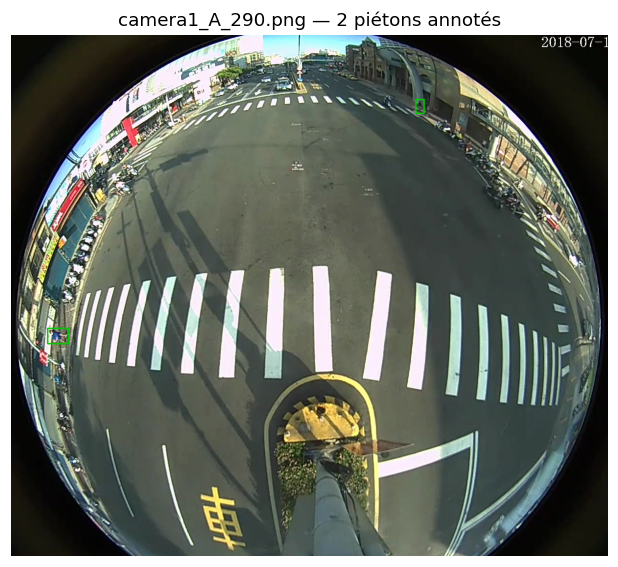

In [11]:
if HAS_GT:
    it = items[0]; img = cv2.imread(str(it["path"]))
    gt = gt_pixels(it, img.shape[1], img.shape[0])
    plt.figure(figsize=(7, 7)); plt.imshow(cv2.cvtColor(draw(img, gt, (0, 200, 0)), cv2.COLOR_BGR2RGB))
    plt.title(f"{it['name']} — {len(gt)} piétons annotés"); plt.axis("off"); plt.show()

## 3. Géométrie (calibration approximative) et contrôles
Un cercle image est estimé par caméra (le bord noir ne bouge pas d'une image à l'autre). Si vous avez la vraie calibration de votre banc, remplacez `EquidistantFisheye` par `KannalaBrandtFisheye(K, D, W, H)`.

In [12]:
by_cam = {}
for it in items:
    h, w = cv2.imread(str(it["path"])).shape[:2]
    it["cam_key"] = f"{it['location']}_{w}x{h}"
    by_cam.setdefault(it["cam_key"], []).append(it)

cams, reps_by_cam, rows = {}, {}, []
for loc, lst in by_cam.items():
    ims = [cv2.imread(str(i["path"])) for i in lst[:10]]
    H, W = ims[0].shape[:2]
    cx, cy, r, fiable = estimate_image_circle(ims)
    cam = EquidistantFisheye(cx, cy, r, FOV_DEG, W, H, name=loc)
    cams[loc] = cam
    reps_by_cam[loc] = make_representations(cam, MONTAGE)
    rows.append(dict(camera=loc, taille=f"{W}x{H}", cx=cx, cy=cy, rayon=r, cercle_fiable=fiable,
                     px_par_degre=cam.f0 * np.pi / 180))
display(pd.DataFrame(rows).round(1))

loc0 = next(iter(by_cam))
chk = []
for name, rep in reps_by_cam[loc0].items():
    for k, (t, lut) in enumerate(rep["views"]):
        fe = t.kind == "fisheye"
        chk.append(dict(representation=name, vue=k, taille=f"{t.W}x{t.H}",
                        aller_retour_px=check_roundtrip(cams[loc0]) if fe else check_target_roundtrip(t),
                        a_l_endroit=None if fe else check_upright(t), part_valide=float(lut.valid.mean())))
display(pd.DataFrame(chk).round(4))

,camera,taille,cx,cy,rayon,cercle_fiable,px_par_degre
0,cam1_1245x1088,1245x1088,619.6,599.2,611.8,True,6.8
1,cam10_1240x1088,1240x1088,621.1,646.1,613.3,True,6.8
2,cam11_1240x1088,1240x1088,604.5,537.8,625.8,True,7.0
3,cam12_1920x1920,1920x1920,947.9,949.4,1103.7,True,12.3
4,cam13_1920x1920,1920x1920,1007.2,916.3,999.5,True,11.1
5,cam14_1920x1088,1920x1088,911.4,467.0,1021.6,True,11.4
6,cam15_1280x1280,1280x1280,656.6,584.5,729.6,True,8.1
7,cam15_1920x1920,1920x1920,976.9,886.1,1080.7,True,12.0
8,cam16_1280x1280,1280x1280,644.1,558.7,650.0,True,7.2
9,cam17_1280x1280,1280x1280,627.0,613.6,741.1,True,8.2


,representation,vue,taille,aller_retour_px,a_l_endroit,part_valide
0,0_brut,0,1245x1088,0.0,None,1.0000
1,1_perspective,0,1349x1349,0.0,None,1.0000
2,2_multivues,0,850x850,0.0,True,0.8180
3,2_multivues,1,850x850,0.0,True,0.8212
4,2_multivues,2,850x850,0.0,True,0.7208
5,2_multivues,3,850x850,0.0,True,0.8212
6,3_cylindrique,0,2583x869,0.0,True,0.9331
7,4_erp,0,2583x612,0.0,True,0.9061


Exemple : une image dans les 5 représentations.

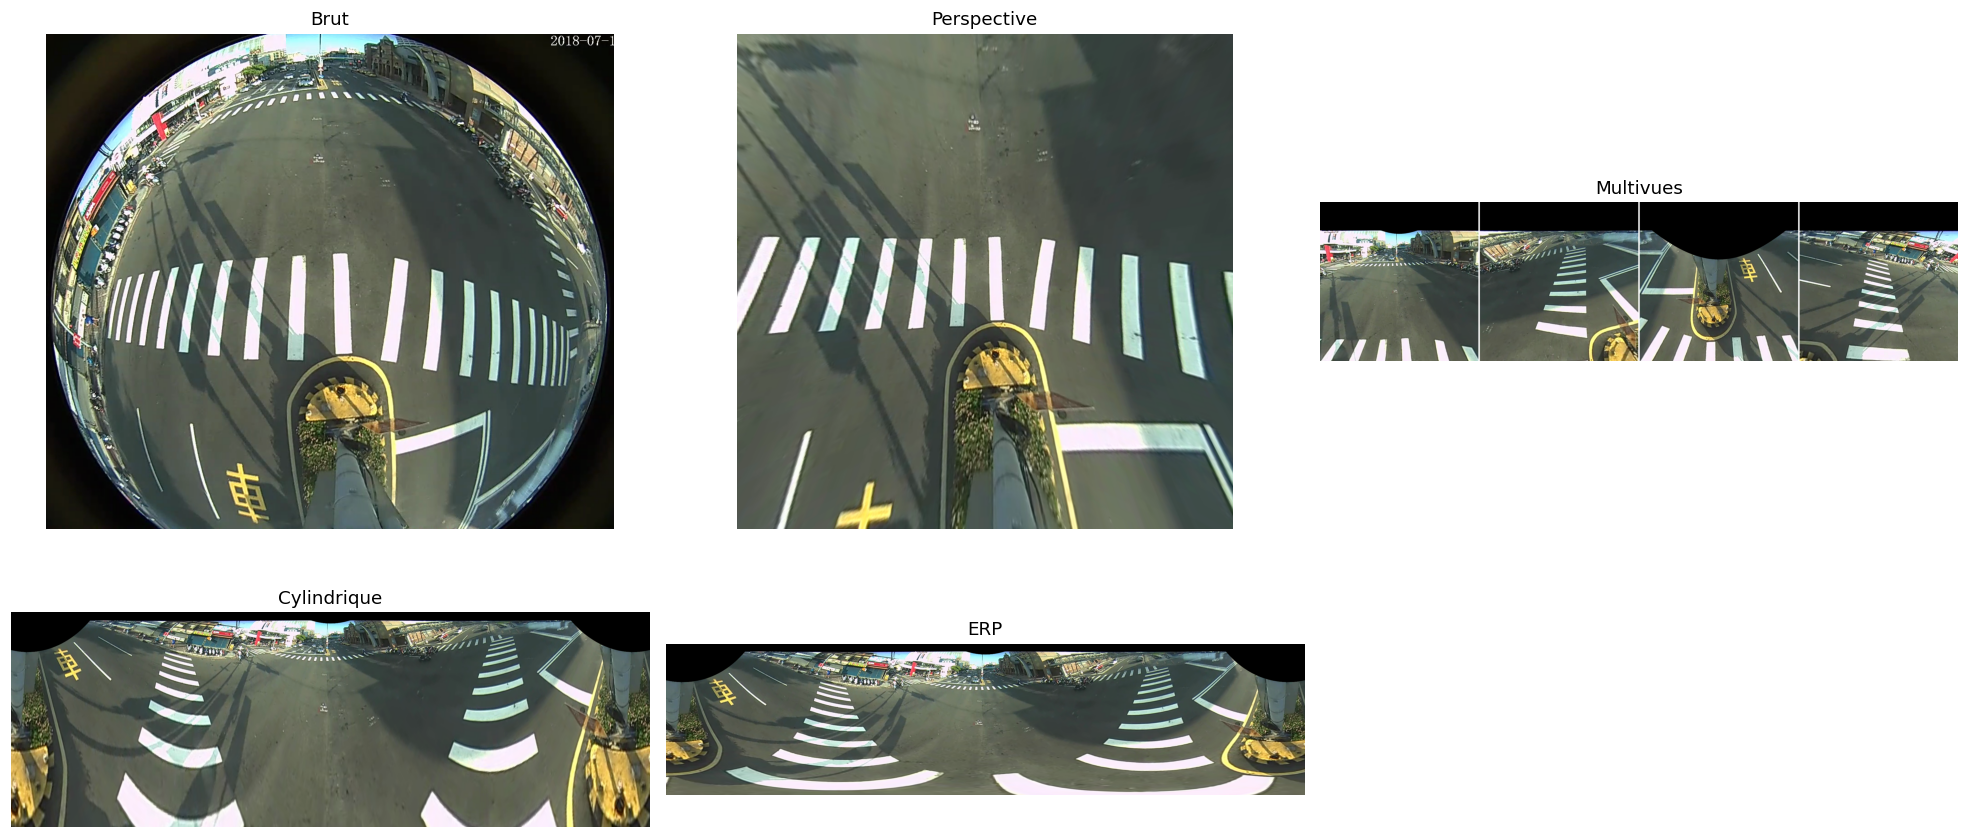

In [13]:
def montage_views(views):
    h = max(v.shape[0] for v in views)
    views = [np.vstack([v, np.zeros((h - v.shape[0], v.shape[1], 3), np.uint8)]) for v in views]
    sep = np.full((h, 8, 3), 255, np.uint8)
    return np.hstack(sum([[v, sep] for v in views], [])[:-1])

it = by_cam[loc0][0]; img = cv2.imread(str(it["path"]))
fig = plt.figure(figsize=(18, 9))
for i, (name, rep) in enumerate(reps_by_cam[loc0].items()):
    ax = fig.add_subplot(2, 3, i + 1)
    ims = [img if t.kind == "fisheye" else lut.remap(img) for t, lut in rep["views"]]
    ax.imshow(cv2.cvtColor(montage_views(ims), cv2.COLOR_BGR2RGB)); ax.set_title(LABELS[name])
    ax.axis("off"); ax.grid(False)
plt.tight_layout(); plt.savefig(FIG / "exemple_representations.png"); plt.show()

## 4. Détection sur chaque représentation
Les images reprojetées sont rangées dans `processed/<représentation>/images`, et les mêmes images avec les détections dans `processed/<représentation>/detections`.

In [15]:
model = YOLO(MODEL)
for t, lut in sum([r["views"] for r in reps_by_cam[loc0].values()], []):   # chauffe
    detect(model, img if t.kind == "fisheye" else lut.remap(img), device=DEVICE)

results = []
for it in tqdm(items, desc="images"):
    img = cv2.imread(str(it["path"])); H, W = img.shape[:2]
    cam, reps = cams[it["cam_key"]], reps_by_cam[it["cam_key"]]
    gt = gt_pixels(it, W, H)
    gt_theta = np.degrees(np.arccos(np.clip(cam.unproject((gt[:, 0] + gt[:, 2]) / 2, (gt[:, 1] + gt[:, 3]) / 2)[:, 2], -1, 1))) if len(gt) else np.zeros(0)
    stem = Path(it["name"]).stem
    for name, rep in reps.items():
        o = run_representation(rep, img, model, conf=0.01, device=DEVICE, keep_images=True)
        keep = o["scores_fe"] >= CONF
        B, S = o["boxes_fe"][keep], o["scores_fe"][keep]
        det_theta = np.degrees(np.arccos(np.clip(cam.unproject((B[:, 0] + B[:, 2]) / 2, (B[:, 1] + B[:, 3]) / 2)[:, 2], -1, 1))) if len(B) else np.zeros(0)
        results.append(dict(image=stem, camera=it["cam_key"], representation=name, n_det=int(keep.sum()),
                            conf_moy=float(S.mean()) if len(S) else np.nan, n_gt=len(gt),
                            trouves_50=match(B, S, gt, 0.5), trouves_30=match(B, S, gt, 0.3),
                            gt_theta=gt_theta, det_theta=det_theta,
                            remap_ms=o["t_remap"], inference_ms=o["t_infer"], fusion_ms=o["t_fuse"]))
        for k, v in enumerate(o["views"]):
            suf = f"_v{k}" if len(o["views"]) > 1 else ""
            for sub, im in (("images", v["image"]),
                            ("detections", draw(v["image"], v["boxes"][v["scores"] >= CONF], (0, 0, 230), v["scores"][v["scores"] >= CONF]))):
                (PROC / name / sub).mkdir(parents=True, exist_ok=True)
                cv2.imwrite(str(PROC / name / sub / f"{stem}{suf}.jpg"), im, [cv2.IMWRITE_JPEG_QUALITY, 92])
res = pd.DataFrame(results)
res.to_pickle(WORK / "resultats.pkl")
print("Terminé :", len(items), "images ×", res.representation.nunique(), "représentations")

images: 100%|██████████| 120/120 [05:24<00:00,  2.71s/it]

Terminé : 120 images × 5 représentations


## 5. Résultats

In [16]:
g = res.groupby("representation")
table = pd.DataFrame({
    "détections / image": g.n_det.mean(),
    "confiance moyenne": g.conf_moy.mean(),
    "remappage (ms)": g.remap_ms.mean(),
    "inférence (ms)": g.inference_ms.mean(),
    "fusion (ms)": g.fusion_ms.mean(),
})
table["total (ms)"] = table[["remappage (ms)", "inférence (ms)", "fusion (ms)"]].sum(axis=1)
if HAS_GT:
    n_gt = res.groupby("representation").n_gt.sum()
    table.insert(0, "rappel IoU≥0,5", g.trouves_50.apply(lambda s: np.concatenate(list(s)).mean()))
    table.insert(1, "rappel IoU≥0,3", g.trouves_30.apply(lambda s: np.concatenate(list(s)).mean()))
    table.insert(2, "piétons annotés", n_gt)
table = table.reindex(REPRESENTATIONS).rename(index=LABELS)
table.to_csv(WORK / "resultats.csv")
display(table.style.format(precision=3))
print(f"Détections comptées à partir d'une confiance de {CONF}. Modèle : {MODEL}.")

,"rappel IoU≥0,5","rappel IoU≥0,3",piétons annotés,détections / image,confiance moyenne,remappage (ms),inférence (ms),fusion (ms),total (ms)
representation,,,,,,,,,
Brut,0.236,0.252,305,1.750,0.470,0.000,282.592,0.031,282.623
Perspective,0.069,0.072,305,0.650,0.455,14.878,487.194,1.651,503.723
Multivues,0.466,0.498,305,4.583,0.463,31.678,657.908,8.547,698.132
Cylindrique,0.397,0.430,305,3.975,0.426,22.654,635.514,6.378,664.546
ERP,0.495,0.554,305,5.358,0.451,17.736,414.634,7.017,439.387


Détections comptées à partir d'une confiance de 0.25. Modèle : yolo26s.pt.


**Lecture.** Le rappel compte les piétons annotés retrouvés par au moins une détection, une fois les boîtes ramenées dans l'image d'origine. Le seuil IoU ≥ 0,3 est donné en plus parce qu'une boîte ramenée depuis une vue redressée est plus large que la boîte annotée (la personne est inclinée dans l'image brute). On ne calcule pas de précision : FishEye8K annote les cyclistes et les personnes à scooter dans la classe *Bike*, alors que YOLO les détecte comme *person*.

## 6. Où ça marche : selon l'angle à l'axe optique θ

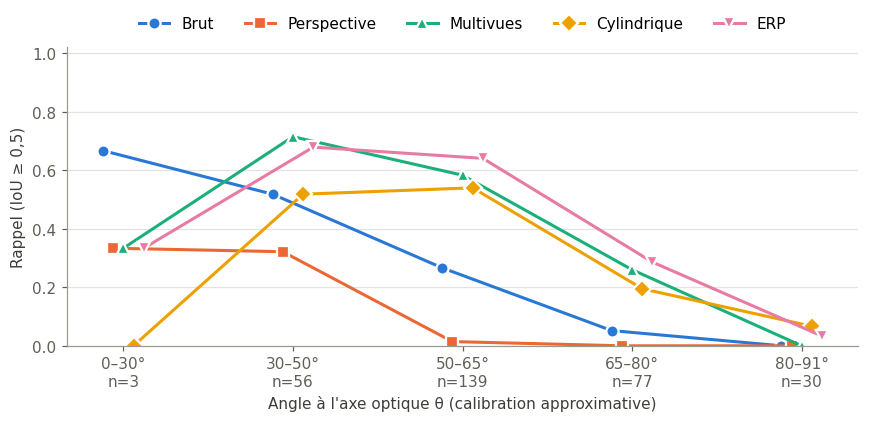

In [17]:
BANDS = [0, 30, 50, 65, 80, 91]
labs = [f"{a}–{b}°" for a, b in zip(BANDS[:-1], BANDS[1:])]
fig, ax = plt.subplots(figsize=(8, 4))
for j, r in enumerate(REPRESENTATIONS):
    sub = res[res.representation == r]
    if HAS_GT:
        th = np.concatenate(list(sub.gt_theta)); ok = np.concatenate(list(sub.trouves_50))
        b = np.digitize(th, BANDS) - 1
        y = [ok[b == k].mean() if (b == k).any() else np.nan for k in range(len(labs))]
        n = [(b == k).sum() for k in range(len(labs))]
    else:
        th = np.concatenate(list(sub.det_theta)) if len(sub) else np.zeros(0)
        b = np.digitize(th, BANDS) - 1
        y = [(b == k).sum() / len(sub.image.unique()) for k in range(len(labs))]
    x = np.arange(len(labs)) + (j - 2) * 0.06
    ax.plot(x, y, color=COLORS[r], marker=MARKERS[r], lw=2, ms=8, markeredgecolor="white",
            markeredgewidth=1.5, label=LABELS[r])
if HAS_GT:
    ax.set_xticks(range(len(labs)), [f"{l}\nn={k}" for l, k in zip(labs, n)])
    ax.set_ylabel("Rappel (IoU ≥ 0,5)"); ax.set_ylim(0, 1.02)
else:
    ax.set_xticks(range(len(labs)), labs); ax.set_ylabel(f"Détections par image (conf ≥ {CONF})")
ax.set_xlabel("Angle à l'axe optique θ (calibration approximative)"); ax.grid(axis="x", visible=False)
ax.legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, 1.15))
plt.tight_layout(); plt.savefig(FIG / "par_theta.png"); plt.show()

## 7. Galerie
Mêmes images, détections ramenées dans l'image d'origine (vert : piétons annotés, rouge : détections).

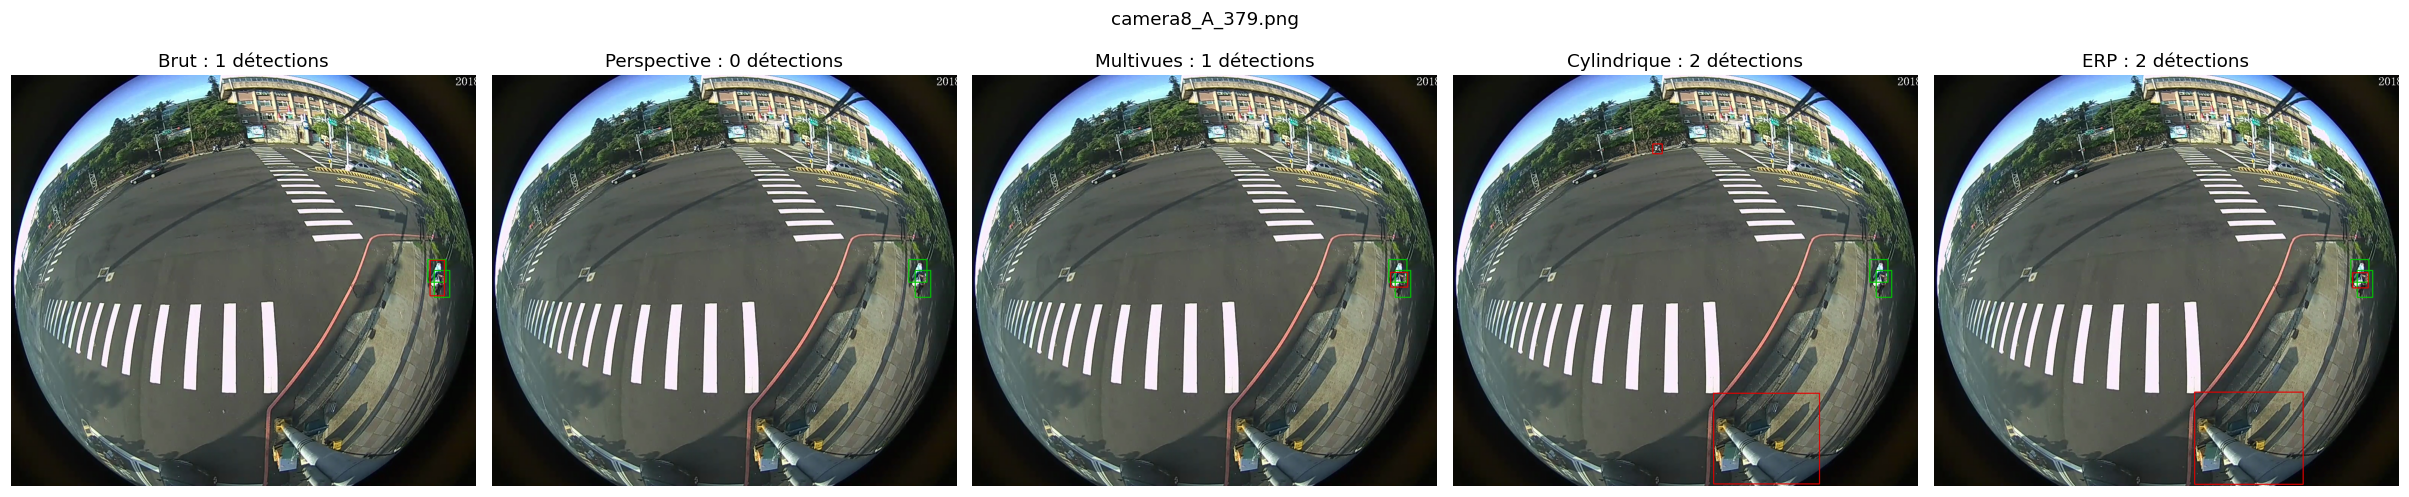

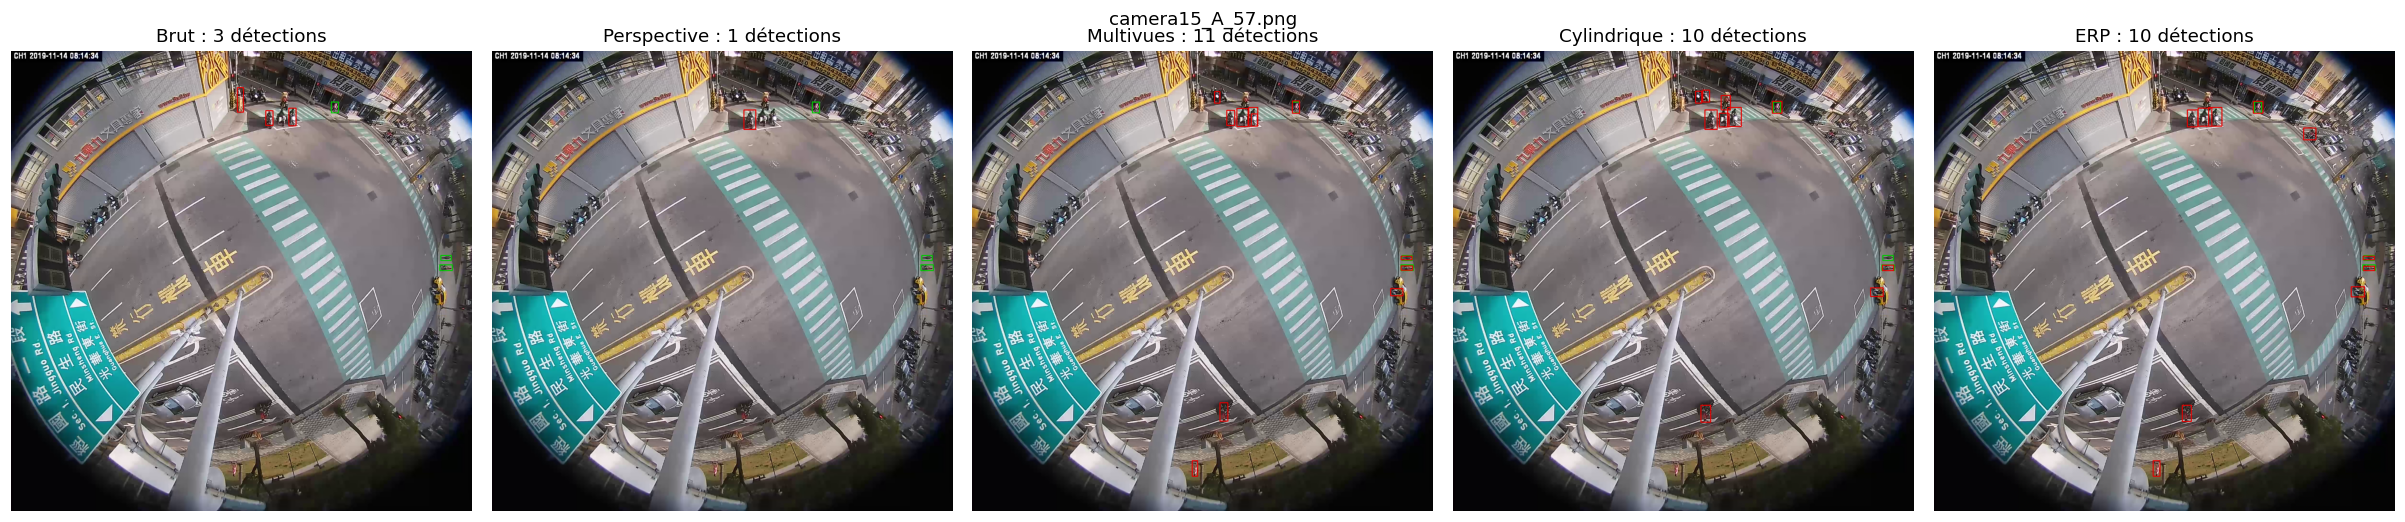

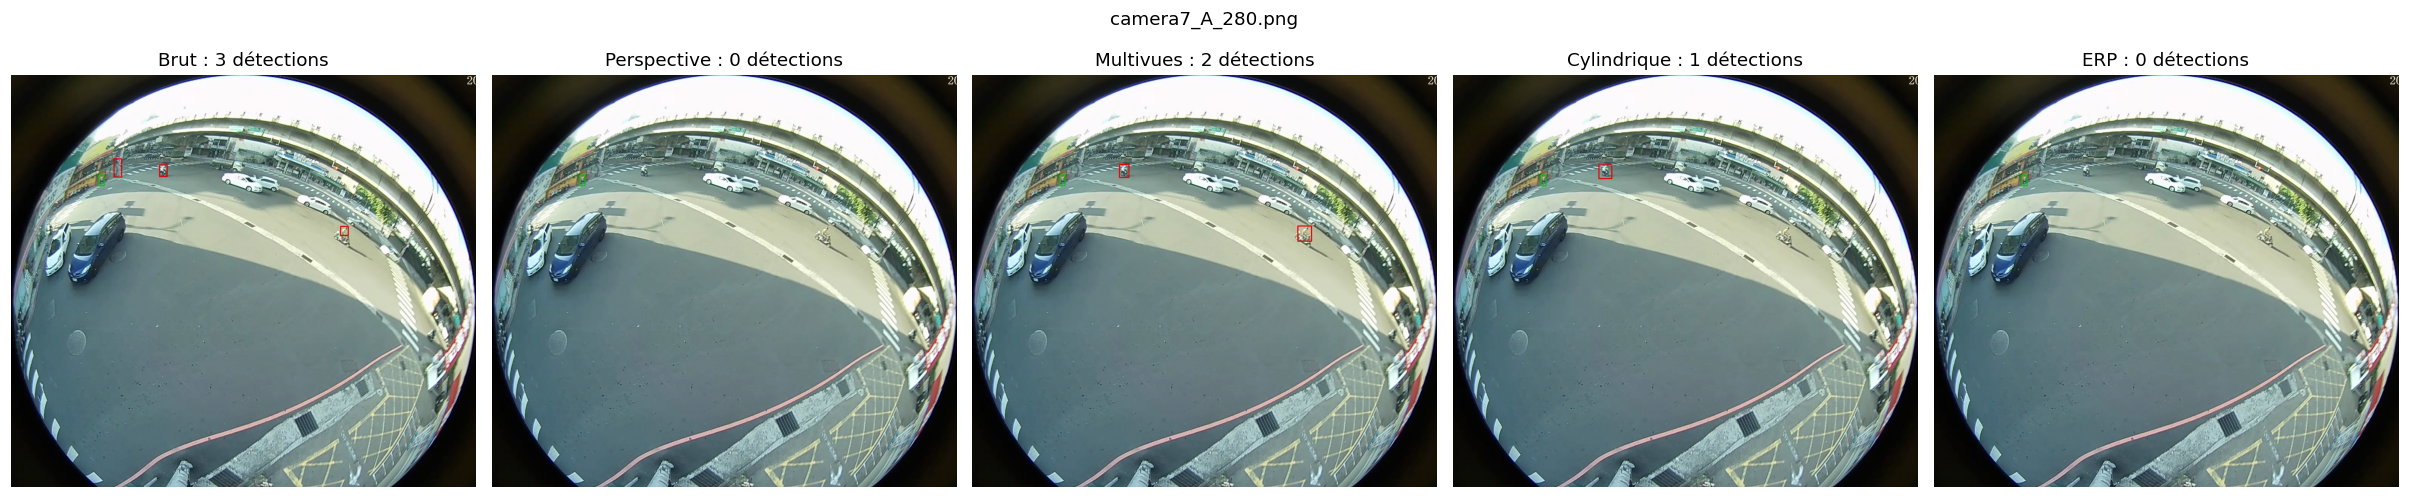

In [19]:
rng = random.Random(SEED)
for it in rng.sample(items, min(3, len(items))):
    img = cv2.imread(str(it["path"])); H, W = img.shape[:2]
    reps = reps_by_cam[it["cam_key"]]; gt = gt_pixels(it, W, H)
    fig, axes = plt.subplots(1, 5, figsize=(22, 4.8))
    for ax, (name, rep) in zip(axes, reps.items()):
        o = run_representation(rep, img, model, conf=CONF, device=DEVICE)
        ax.imshow(cv2.cvtColor(draw(draw(img, gt, (0, 200, 0)), o["boxes_fe"], (0, 0, 230)), cv2.COLOR_BGR2RGB))
        ax.set_title(f"{LABELS[name]} : {len(o['boxes_fe'])} détections"); ax.axis("off"); ax.grid(False)
    plt.suptitle(it["name"]); plt.tight_layout()
    plt.savefig(FIG / f"galerie_{Path(it['name']).stem}.png"); plt.show()

## 8. Limites de ce test

- **Calibration approximative** : modèle équidistant de 180° supposé, cercle estimé sur l'image. Les angles θ et les reprojections sont donc indicatifs ; avec la vraie calibration (`KannalaBrandtFisheye`), les résultats seront plus fiables.
- **FishEye8K est en vue plongeante** : le cylindre y tourne autour de l'axe optique (panorama 360°). C'est un autre cas que votre banc à hauteur d'homme, où le cylindre tourne autour de la verticale devant la caméra (`MONTAGE = "horizontal"`). Les tendances observées ici ne se transposent pas directement : il faudra refaire le test avec des images du banc.
- **Résolution** : toutes les représentations ont la même résolution angulaire au centre et YOLO reçoit les images sans réduction. Les panoramas 360° sont donc larges (≈ 2 200 px), d'où une inférence plus longue.